In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# **Task 0**
**what does the NEIG-##### ticket number actually represent?**  
It is an identifier for a response from a person. Sub tickets/follow up responses will have new ticket numbers but tie back to the same person in summary.
  
    
**Why are ticket numbers not sequential per family?**  
Tickets numbers are sequential in order of creation and new people make tickets between the same person sending in multiple tickets.  

**What does Issue Type tell you about which rows are new intakes versus sub-tickets tied to an existing case?**  
Some issue types 'New Profile', 'Connected Neighbor Account', and 'Flourishing Neighbor Profile' correspond to a first ticket. The parent fields are all blank for these issue types.  
All other issue types correspond to subtickets of another ticket, which is referenced in the parent ticket columns.


# Task 1  
**1.
Fill in Figures 1 and 2 above using the real data — show your work (the code and the numbers), not just the final diagram.**

# **Figure 1:**
---
Reconnect total: **426 tickets**


*   Housing Stable: **244** (Not Eviction Risk and not Unhoused)
*   Eviction Risk: **167** (Being evicted OR 7 day notice OR rent past due OR utilities past due)
*   Unhoused: **13**
*   Excess Subtickets: **213** (Not needed)

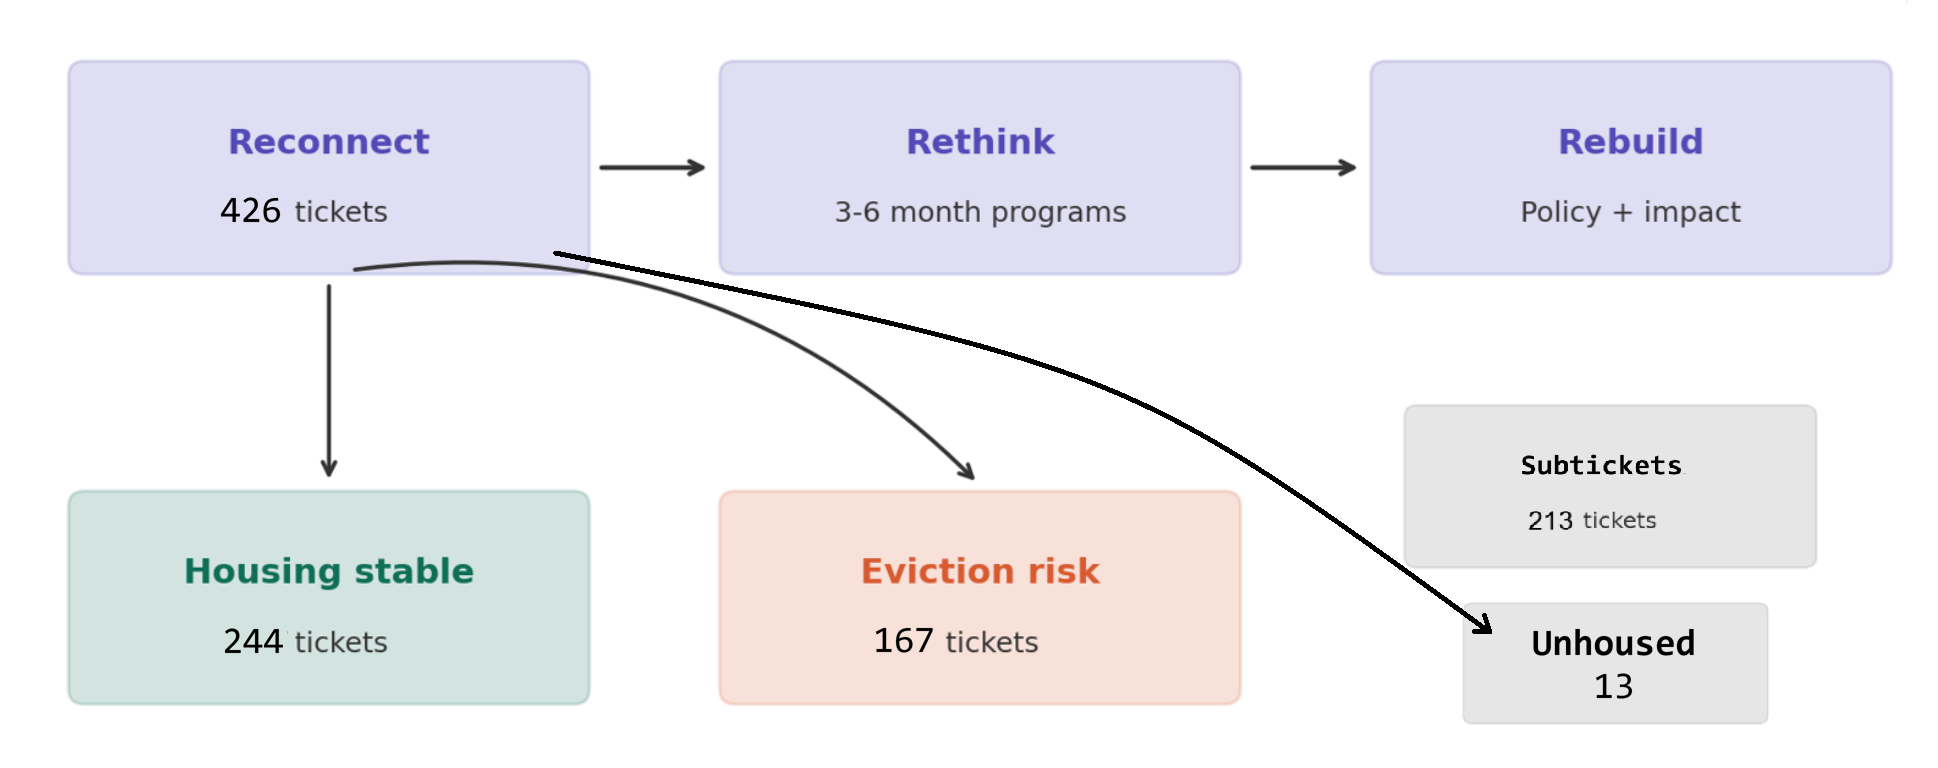

# Figure 2:
---
Total: **426** (excluding subtickets)

24 entries have 2 profiles,
2 have 3,
and 1 has 4.

426-(24+4+3) = **395** unique profiles

*   Episodic, Less Urgent: 262 (1 intake profile, not currently being evicted and not unhoused)
*   Episodic, Urgent: 106 (1 intake profile, currently being evicted or unhoused)
*   Chronic, Less Urgent: 23 (2+ intake profiles, not currently being evicted and not unhoused)
*   Chronic, Urgent: 10 (2+ intake profiles, currently being evicted or unhoused)




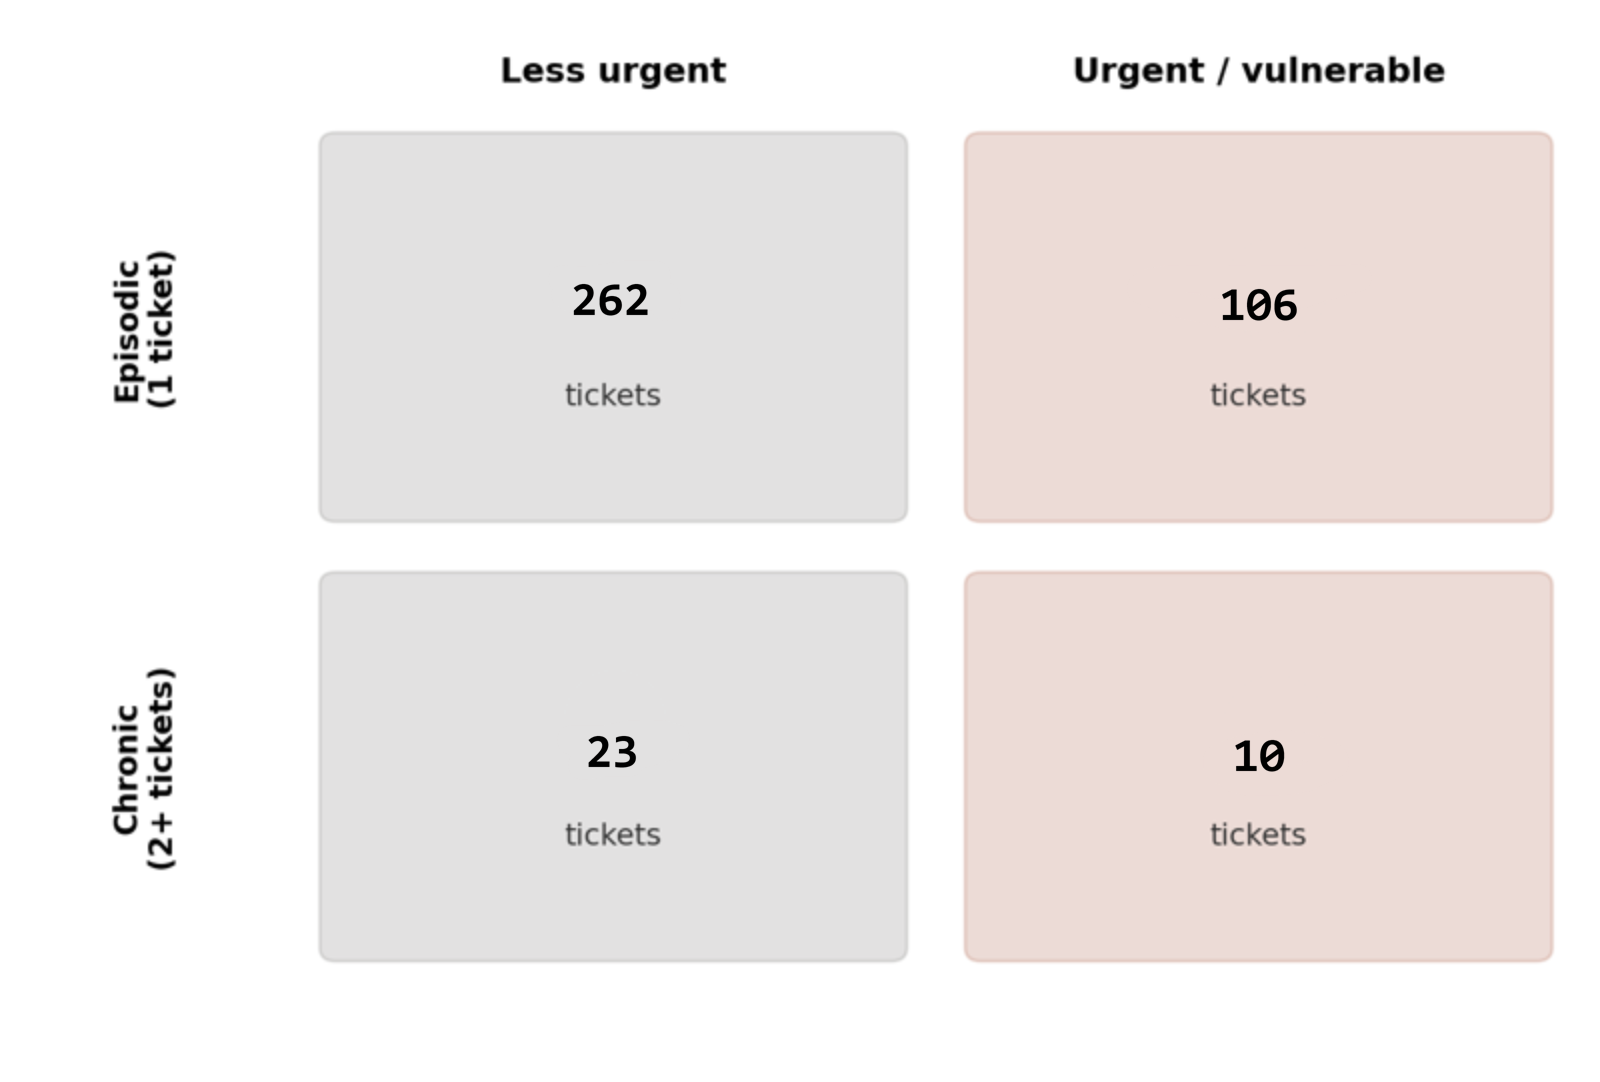

In [2]:
import pandas as pd
# raw_intakes = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Module 1/Group1_Project/raw_cleaned_intakes_masked(1).csv')
# raw_household = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Module 1/Group1_Project/raw_household_members_long_v2(1).csv')

intakes = pd.read_csv("cleaned_intakes_masked.csv")
household = pd.read_csv("household_members_long_v2.csv")


In [3]:
clean_intakes = intakes.copy()

In [4]:
# keep only true intake profiles
profile_types = [
    'New Profile',
    'Connected Neighbor Profile',
    'Flourishing Neighbor Profile'
]

profiles = clean_intakes[
    clean_intakes['Issue Type'].isin(profile_types)
].copy()

print("Profile rows:", len(profiles))

Profile rows: 426


**Stable/At Risk Housing Split (Figure 1)**

In [5]:
import numpy as np

profiles['Housing Risk Category'] = 'Stable'

#The Unhoused
profiles.loc[profiles['Custom field (Housing Status)'] == 'Unhoused', 'Housing Risk Category'] = 'Unhoused'


at_risk_conditions = (
    profiles['Custom field (Eviction Status)'].isin(['Currently being evicted', 'Received 7 day notice']) |
    (profiles['Custom field (Past Due Rent ($))'].notna() & (profiles['Custom field (Past Due Rent ($))'] > 0)) |
    (profiles['Custom field (Utility Past Due)'].value_counts(dropna=False))
)

profiles.loc[at_risk_conditions & (profiles['Housing Risk Category'] != 'Unhoused'), 'Housing Risk Category'] = 'At-risk/Vulnerable'

unknown_risk_factor_conditions = (
    profiles['Custom field (Eviction Status)'].isna() &
    profiles['Custom field (Past Due Rent ($))'].isna() &
    profiles['Custom field (Utility Past Due)'].isna()
)

profiles.loc[unknown_risk_factor_conditions & (profiles['Housing Risk Category'] == 'Stable'), 'Housing Risk Category'] = 'Unknown Risk'

print("Housing Risk Category Distribution:")
print(profiles['Housing Risk Category'].value_counts())

Housing Risk Category Distribution:
Housing Risk Category
Stable                244
At-risk/Vulnerable    167
Unhoused               15
Name: count, dtype: int64


/tmp/ipykernel_624/3100359113.py:10: FutureWarning: Operation between non boolean Series with different indexes will no longer return a boolean result in a future version. Cast both Series to object type to maintain the prior behavior.
  profiles['Custom field (Eviction Status)'].isin(['Currently being evicted', 'Received 7 day notice']) |


**Chronic/Episodic Split per Housing Status (Figure 2)**

In [6]:
# Assignment definition of urgency
profiles['Urgency'] = 'Less Urgent'

profiles.loc[
    (profiles['Custom field (Eviction Status)'] == 'Currently being evicted') |
    (profiles['Custom field (Housing Status)'] == 'Unhoused'),
    'Urgency'
] = 'Urgent'

# 1. Count total tickets per PID across the entire intakes DataFrame
total_ticket_counts_per_pid = profiles['PID'].value_counts()

# 2. Map PIDs to 'Episodic' (1 ticket) or 'Chronic' (multiple tickets)
def categorize_contact_frequency(pid):
    if pid in total_ticket_counts_per_pid:
        if total_ticket_counts_per_pid[pid] > 1:
            return 'Chronic'
        else:
            return 'Episodic'
    return 'Unknown'

profiles['Contact_Frequency'] = profiles['PID'].apply(categorize_contact_frequency)

# 3. Combine with Housing Risk Category and count unique individuals
# We want to count unique people (PIDs) for each combination of categories

# Create a temporary DataFrame with unique PID and their classifications
pid_housing_contact_df = profiles[['PID', 'Urgency', 'Contact_Frequency']].drop_duplicates()

# Group by Housing Risk Category and Contact_Frequency and count unique PIDs
risk_frequency_distribution = pid_housing_contact_df.groupby(
    ['Urgency', 'Contact_Frequency']
)['PID'].nunique().unstack(fill_value=0)

print("Distribution of Housing Risk Category by Contact Frequency (Episodic/Chronic):")
print(risk_frequency_distribution)

Distribution of Housing Risk Category by Contact Frequency (Episodic/Chronic):
Contact_Frequency  Chronic  Episodic
Urgency                             
Less Urgent             23       262
Urgent                  10       106


In [7]:
print(profiles['PID'].nunique())

395


In [8]:
print(profiles['PID'].value_counts().value_counts().sort_index())

count
1    368
2     24
3      2
4      1
Name: count, dtype: int64


2.  
**Build a column triage table: go through all 93 columns in cleaned_intakes_masked.csv and classify each as Needed, Optional, or Drop for this phase, with a one-line reason for each. Many columns are Jira system fields (staff names, internal IDs, board sort order) rather than case data — part of the exercise is telling those apart from columns that actually describe a family's situation.**

**PID**: Needed - to match tickets to people  
**PID Match Basis:** Drop - we dont care how they were matched  
**Summary:** Drop - redundant info to PID  
**Issue key:** Needed - Unique identifier for a ticket  
**Issue id:** Drop - redundant to Issue key  
**Issue Type:** Needed - unknown future question to answer but seems relevant  
**Status:** Drop - current ticket status isnt relevant to family situation  
**Resolution:** Drop - Do/Wont Do isnt helpful info for us to train on later  
**Reporter:** Drop - dont need to know when who the reporter is  
**Reporter Id:** Drop - dont need to know when who the reporter is  
**Creator:** Drop - dont need to know when who the creator is  
**Creator Id:** Drop - dont need to know when who the creator is  
**Created:** Needed - order a persons tickets if needed  
**Updated:** Drop - dont need to know when when it was updated last   
**Resolved:** Drop - dont need to know when it was resolved  
**Labels.1:** Needed - seems difficult to work with but relevant to a family situation  
**Labels.2:** Needed - seems difficult to work with but relevant to a family situation  
**Labels.3:** Needed - seems difficult to work with but relevant to a family situation  
**Labels.4:** Needed - seems difficult to work with but relevant to a family situation  
**Labels.5:** Needed - seems difficult to work with but relevant to a family situation  
**Labels.6:** Needed - seems difficult to work with but relevant to a family situation  
**Watchers:** Drop - we dont need to know internally who is watching a ticket  
**Watchers.1:** Drop - we dont need to know internally who is watching a ticket  
**Watchers Id:** Drop - we dont need to know internally who is watching a ticket  
**Watchers Id.1:** Drop - we dont need to know internally who is watching a ticket  
**# Additional Household Members:** Needed - family relevant info  
**Custom field (City):** Needed - The city they live in is relevant  
**Custom field (Community Ministry):** Drop - we dont need to know their ministry  
**Custom field (Court Date):** Drop - we dont need to know + all dates are past already  
**Custom field (Current Employer):** Drop - redundant to Custom field (Employment Status)  
**Age at Intake:** Needed - client age is relevant  
**Custom field (Employment Status):** Needed - employment status is relevant to us  
**Custom field (Eviction Reason):** Drop - lack of details largely similar options  
**Custom field (Eviction Status):** Needed - shows urgency of need  
**Custom field (Gender):** Needed - can be used for comparisons  
**Custom field (Goals):** Needed - difficult to use but relevant   
**Custom field (Goals).1:** Needed - difficult to use but relevant   
**Custom field (Goals).2:** Needed - difficult to use but relevant  
**Custom field (Goals).3:** Needed - difficult to use but relevant    
**Custom field (Household Identities):** Needed - shows chronic/urgencyness  
**Custom field (Household Identities).1:** Needed - shows chronic/urgencyness  
**Custom field (Household repairs required?):** Needed - shows need  
**Custom field (Housing Status):** Needed - shows urgency  
**Custom field (Income Amount ($)):** Needed - shows need  
**Custom field (Insurance Provider for Family):** Needed but binary encode to if they have or dont have insurance  
**Custom field (Intake Date):** Drop - irrelevant to us  
**Has LG&E Account on File:** Drop - on file/not doesnt help us either way  
**Custom field (Landlord Name):** Drop - we dont need to know their landlord name  
**Comment:** Drop - not analysable field  
**Comment.1:** Drop - not analysable field  
**Comment.2:** Drop - not analysable field  
**Status Category Changed:** Drop - not relevant to family situation  
**Status Category:** Drop - not family situation relevant  
**Custom field ([CHART] Time in Status)	:** Drop - not family situation relevant  
**Custom field ([CHART] Date of First Response):** Drop - notn family stituation relevant  
**Custom field (Zip Code):** Needed - location is relevant  
**Has Water Account on File:** Drop - we dont need to know what they have on file  
**Custom field (Utility Past Due):** Needed - shows urgency  
**Custom field (State):** Drop - its all kentucky
**Custom field (Rent-to-Income %):** Needed - shows need amt  
**Custom field (Response Method):** Drop - not relevant  
**Custom field (Response Method).1:** Drop - not relevant  
**Custom field (Section 8 or Housing Voucher):** Needed - shows outside help  
**Custom field (Source of income):** Needed - see where they get money  
**Custom field (Source of income).1:** Needed - see where they get money  
**Status Category:** Drop - not relevant to family situation  
**Parent:** Needed - unknown use but applicable to parent tickets  
**Parent summary:** Drop - Contains PII  
**Parent key:** Needed - has Issue key of parent tickets   
**Custom field (Rank):** Drop - seems like nonsense, probably internally used  
**Custom field (Rent Intake Form Goals):** Needed - difficult to use but relevant  
**Custom field (Rent Intake Form Goals).1:** Needed - difficult to use but relevant  
**Custom field (Rent Intake Form Goals).2:** Needed - difficult to use but relevant  
**Custom field (Rent Intake Form Goals).3:** Needed - difficult to use but relevant  
**Custom field (Pronoun):** Drop - redundant to gender  
**Custom field (Race/Ethnicity):** Needed - useful for comparison  
**Custom field (Primary Language Spoken in Home):** Drop - not relevant and 90%+ of values are english or na  
**Custom field (Primary Insurance):** Needed - for comparison and relevant
**Custom field (Loss of Income Causation):** Needed - good for analysis   
**Custom field (Loss of Income Causation).1:** Needed - good for analysis   
**Custom field (Loss of Income Causation).2:** Needed - good for analysis   
**Custom field (Loss of Income Causation).3:** Needed - good for analysis   
**Custom field (Main reason Neighbor stopped paying rent):** Needed - relevant to situation  
**Custom field (Monthly Rent (\$)):** Needed - rent is very relevant  
**Has Email on File:** Drop - internal flag  
**Has Phone on File:** Drop - internal flag  
**Custom field (Other Professionals Detail):** Drop - way too much varitety to hold any useful info  
**Custom field (Other professionals helping with goals?):** Needed - shows urgency/external help  
**Custom field (Past Due Rent (\$)):** Needed - shows urgency  
**Custom field (People in Household 17 and Under):** Needed - shows need  
**Custom field (People in Household 18+):** Needed - shows need  
**Custom field (People in Household 65+):** Needed - shows need  
**Custom field (Preferred method of contact):** Drop - internal info  
**Custom field (Preferred method of contact).1:** Drop - internal info  

3.
**Identify, in writing, which parts of the partner's plan the data does NOT currently support (for example: is there a field that captures the Rethink or Rebuild stage? If not, what would you propose SLCM start collecting?).**  

I think this data covers all parts of the plan adequately. Earlier we used data for the Reconnect portion already.
Rebuild is focusing on making sure it doesn't happen again and I feel that the 'loss of income causation' columns are perfect for this, identifying the source of the problem to work preventatively in the future.
For the Rebuild phase, there are a variety of fields to look for potential subgroups of people disproportionally impacted such as race, some of the label columns, and the zip code column.

# Task 2  
4.
**Summarize both files: row/column counts, data types, a data dictionary built from your Task 1 triage.**

In [9]:
import pandas as pd

print("intakes shape:", intakes.shape)
print("household shape:", household.shape)


print("\nIntakes DataFrame dtypes:")
print(intakes.dtypes)

print("\nHousehold DataFrame dtypes:")
print(household.dtypes)

intakes shape: (639, 93)
household shape: (993, 8)

Intakes DataFrame dtypes:
PID                         object
PID Match Basis             object
Summary                     object
Issue key                   object
Issue id                     int64
                            ...   
Parent                     float64
Parent key                  object
Parent summary              object
Status Category             object
Status Category Changed     object
Length: 93, dtype: object

Household DataFrame dtypes:
PID                object
Member ID          object
Issue key          object
Member #            int64
Age               float64
Gender             object
Race/Ethnicity     object
Relationship       object
dtype: object


### Intakes DataFrame Data Dictionary

| Column Name                       | Data Type | Triage   | Reason                                                  |
|:----------------------------------|:----------|:---------|:--------------------------------------------------------|
| `PID`                             | object    | Needed   | to match tickets to people                              |
| `PID Match Basis`                 | object    | Drop     | we don't care how they were matched                     |
| `Summary`                         | object    | Drop     | redundant info to PID                                   |
| `Issue key`                       | object    | Needed   | Unique identifier for a ticket                          |
| `Issue id`                        | int64     | Drop     | redundant to Issue key                                  |
| `Issue Type`                      | object    | Needed   | unknown future question to answer but seems relevant    |
| `Status`                          | object    | Drop     | current ticket status isn't relevant to family situation|
| `Resolution`                      | object    | Drop     | Do/Wont Do isn't helpful info for us to train on later  |
| `Reporter`                        | object    | Drop     | don't need to know when who the reporter is             |
| `Reporter Id`                     | object    | Drop     | don't need to know when who the reporter is             |
| `Creator`                         | object    | Drop     | don't need to know when who the creator is              |
| `Creator Id`                      | object    | Drop     | don't need to know when who the creator is              |
| `Created`                         | object    | Needed   | order a person's tickets if needed                      |
| `Updated`                         | object    | Drop     | don't need to know when when it was updated last        |
| `Resolved`                        | object    | Drop     | don't need to know when it was resolved                 |
| `Labels.1`                        | object    | Needed   | seems difficult to work with but relevant               |
| `Labels.2`                        | object    | Needed   | seems difficult to work with but relevant               |
| `Labels.3`                        | object    | Needed   | seems difficult to work with but relevant               |
| `Labels.4`                        | object    | Needed   | seems difficult to work with but relevant               |
| `Labels.5`                        | object    | Needed   | seems difficult to work with but relevant               |
| `Labels.6`                        | object    | Needed   | seems difficult to work with but relevant               |
| `Watchers`                        | float64   | Drop     | we don't need to know internally who is watching a ticket|
| `Watchers.1`                      | float64   | Drop     | we don't need to know internally who is watching a ticket|
| `Watchers Id`                     | float64   | Drop     | we don't need to know internally who is watching a ticket|
| `Watchers Id.1`                   | float64   | Drop     | we don't need to know internally who is watching a ticket|
| `# Additional Household Members`    | float64   | Needed   | family relevant info                                    |
| `Custom field (City)`             | object    | Needed   | The city they live in is relevant                       |
| `Custom field (Community Ministry)`| object    | Drop     | we don't need to know their ministry                    |
| `Custom field (Court Date)`       | object    | Drop     | we don't need to know + all dates are past already      |
| `Custom field (Current Employer)` | object    | Drop     | redundant to Custom field (Employment Status)           |
| `Age at Intake`                   | float64   | Needed   | client age is relevant                                  |
| `Custom field (Employment Status)`| object    | Needed   | employment status is relevant to us                     |
| `Custom field (Eviction Reason)`  | object    | Drop     | lack of details largely similar options                 |
| `Custom field (Eviction Status)`  | object    | Needed   | shows urgency of need                                   |
| `Custom field (Gender)`           | object    | Needed   | can be used for comparisons                             |
| `Custom field (Goals)`            | object    | Needed   | difficult to use but relevant                           |
| `Custom field (Goals).1`          | object    | Needed   | difficult to use but relevant                           |
| `Custom field (Goals).2`          | object    | Needed   | difficult to use but relevant                           |
| `Custom field (Goals).3`          | object    | Needed   | difficult to use but relevant                           |
| `Custom field (Household Identities)`| object    | Needed   | shows chronic/urgency                                   |
| `Custom field (Household Identities).1`| object | Needed   | shows chronic/urgency                                   |
| `Custom field (Household repairs required?)`| object | Needed | shows need                                              |
| `Custom field (Housing Status)`   | object    | Needed   | shows urgency                                           |
| `Custom field (Income Amount ($))`| float64   | Needed   | shows need                                              |
| `Custom field (Insurance Provider for Family)`| object | Needed | Needed but binary encode to if they have or don't have insurance|
| `Custom field (Intake Date)`      | object    | Drop     | irrelevant to us                                        |
| `Has LG&E Account on File`        | object    | Drop     | on file/not doesn't help us either way                  |
| `Custom field (Landlord Name)`    | object    | Drop     | we don't need to know their landlord name               |
| `Comment`                         | object    | Drop     | not analyzable field                                    |
| `Comment.1`                       | object    | Drop     | not analyzable field                                    |
| `Comment.2`                       | object    | Drop     | not analyzable field                                    |
| `Status Category Changed`         | object    | Drop     | not relevant to family situation                        |
| `Status Category`                 | object    | Drop     | not family situation relevant                           |
| `Custom field ([CHART] Time in Status)`| float64 | Drop   | not family situation relevant                           |
| `Custom field ([CHART] Date of First Response)`| object | Drop | not family situation relevant                           |
| `Custom field (Zip Code)`         | object    | Needed   | location is relevant                                    |
| `Has Water Account on File`       | object    | Drop     | we don't need to know what they have on file            |
| `Custom field (Utility Past Due)` | object    | Needed   | shows urgency                                           |
| `Custom field (State)`            | object    | Drop     | it's all Kentucky                                       |
| `Custom field (Rent-to-Income %)` | float64   | Needed   | shows need amt                                          |
| `Custom field (Response Method)`  | object    | Drop     | not relevant                                            |
| `Custom field (Response Method).1`| object    | Drop     | not relevant                                            |
| `Custom field (Section 8 or Housing Voucher)`| object | Needed | shows outside help                                      |
| `Custom field (Source of income)` | object    | Needed   | see where they get money                                |
| `Custom field (Source of income).1`| object | Needed   | see where they get money                                |
| `Parent`                          | float64   | Needed   | unknown use but applicable to parent tickets            |
| `Parent summary`                  | object    | Drop     | Contains PII                                            |
| `Parent key`                      | object    | Needed   | has Issue key of parent tickets                         |
| `Custom field (Rank)`             | float64   | Drop     | seems like nonsense, probably internally used           |
| `Custom field (Rent Intake Form Goals)`| object | Needed | difficult to use but relevant                           |
| `Custom field (Rent Intake Form Goals).1`| object | Needed | difficult to use but relevant                           |
| `Custom field (Rent Intake Form Goals).2`| object | Needed | difficult to use but relevant                           |
| `Custom field (Rent Intake Form Goals).3`| object | Needed | difficult to use but relevant                           |
| `Custom field (Pronoun)`          | object    | Drop     | redundant to gender                                     |
| `Custom field (Race/Ethnicity)`   | object    | Needed   | useful for comparison                                   |
| `Custom field (Primary Language Spoken in Home)`| object | Drop | not relevant and 90%+ of values are English or NA       |
| `Custom field (Primary Insurance)`| object    | Needed   | for comparison and relevant                             |
| `Custom field (Loss of Income Causation)`| object | Needed | good for analysis                                       |
| `Custom field (Loss of Income Causation).1`| object | Needed | good for analysis                                       |
| `Custom field (Loss of Income Causation).2`| object | Needed | good for analysis                                       |
| `Custom field (Loss of Income Causation).3`| object | Needed | good for analysis                                       |
| `Custom field (Main reason Neighbor stopped paying rent)`| object | Needed | relevant to situation                                   |
| `Custom field (Monthly Rent ($))` | float64   | Needed   | rent is very relevant                                   |
| `Has Email on File`               | object    | Drop     | internal flag                                           |
| `Has Phone on File`               | object    | Drop     | internal flag                                           |
| `Custom field (Other Professionals Detail)`| object | Drop | way too much variety to hold any useful info            |
| `Custom field (Other professionals helping with goals?)`| object | Needed | shows urgency/external help                             |
| `Custom field (Past Due Rent ($))`| float64   | Needed   | shows urgency                                           |
| `Custom field (People in Household 17 and Under)`| float64 | Needed | shows need                                              |
| `Custom field (People in Household 18+)`| float64 | Needed | shows need                                              |
| `Custom field (People in Household 65+)`| float64 | Needed | shows need                                              |
| `Custom field (Preferred method of contact)`| object | Drop | internal info                                           |
| `Custom field (Preferred method of contact).1`| object | Drop | internal info                                           |

### Household DataFrame Data Dictionary

| Column Name    | Data Type | Triage | Reason |
|:---------------|:----------|:-------|:-------|
| `PID`          | object    | Needed | to match tickets to people |
| `Member ID`    | object    | Needed | unique identifier for each household member |
| `Issue key`    | object    | Needed | to link household members to specific intake tickets |
| `Member #`     | int64     | Needed | to identify the order of members within a household |
| `Age`          | float64   | Needed | important demographic information for analysis |
| `Gender`       | object    | Needed | important demographic information for analysis |
| `Race/Ethnicity`| object    | Needed | important demographic information for analysis |
| `Relationship` | object    | Needed | to understand household structure |


**5.	Explore each variable you kept. Focus on the ones that look unusual — skewed distributions, unexpected missingness, outliers, or values that don't make sense.**

## Notes

**Intake File**

Custom field (Income Amount ($)) has max value of 75000

Custom field (Monthly Rent ($)) has max value of 125100.00

Custom field (Past Due Rent ($)) has max value of 242682.00

378 new profile, 44 connected neighbor, 4 flouris (unique ppl talked to)

213 nan is good. means all subtickets didn't give dupe info

Custom field (City) needs similar name cleaning

NaN on Custom field (Utility Past Due) a little high (391) - can't do anything about it though

age at intake has 0 values, need to clean

past due rent might have a few outliers, set a hard cap


**Household File**

605 missing race values - can't do much about it but noteworthy

Age max value 1824

Race/Ethnicity needs similar name cleaning

6.
**Clean what needs cleaning, and document every decision. Don't silently fix things.**

### Intakes Cleaning

Change values in Custom field (Income Amount ($)) to NaN if they exceeds 10000

In [10]:
print(clean_intakes['Custom field (Income Amount ($))'].isna().sum())
clean_intakes.loc[clean_intakes['Custom field (Income Amount ($))'] > 10000, 'Custom field (Income Amount ($))'] = float('nan')
print(clean_intakes['Custom field (Income Amount ($))'].isna().sum())

213
219


Set outlier value in Custom field (Monthly Rent ($)) to NaN if they exceed 5000

In [11]:
print(clean_intakes['Custom field (Monthly Rent ($))'].isna().sum())
clean_intakes.loc[clean_intakes['Custom field (Monthly Rent ($))'] >= 5000, 'Custom field (Monthly Rent ($))'] = float('nan')
print(clean_intakes['Custom field (Monthly Rent ($))'].isna().sum())

471
472


Set 0utlier values in Custom field (Past Due Rent ($)) to NaN if they exceed 15999

In [12]:
print(clean_intakes['Custom field (Past Due Rent ($))'].isna().sum())
clean_intakes.loc[clean_intakes['Custom field (Past Due Rent ($))'] > 15999, 'Custom field (Past Due Rent ($))'] = float('nan')
print(clean_intakes['Custom field (Past Due Rent ($))'].isna().sum())

475
477


Standardize capitalization and spelling in Custom field (City)

In [13]:
import numpy as np

# 1. turn any existing "nan"/"Nan" text back into real missing values
clean_intakes['Custom field (City)'] = clean_intakes['Custom field (City)'].replace(
    {'Nan': np.nan, 'nan': np.nan, 'NaN': np.nan}
)
print(clean_intakes['Custom field (City)'].isna().sum())  # before

# 2. clean the spelling WITHOUT astype(str), so missing values stay missing
city = clean_intakes['Custom field (City)'].str.lower().str.strip()
city = city.replace({
    'lousville': 'louisville',
    'louisvile': 'louisville',
    'louisvill': 'louisville',
    'louisvlle': 'louisville',
    'louisville ky': 'louisville'
})
clean_intakes['Custom field (City)'] = city.str.title()

print(clean_intakes['Custom field (City)'].isna().sum())  # after

215
215


In [14]:
clean_intakes['Custom field (City)'].value_counts(dropna=False)

,count
Custom field (City),
Louisville,407
NaN,215
Fairdale,13
Prospect,2
Shivley,1
Boston,1


In [15]:
# Display value counts after cleaning
print("Value counts after cleaning:")
display(clean_intakes['Custom field (City)'].value_counts())

Value counts after cleaning:


,count
Custom field (City),
Louisville,407
Fairdale,13
Prospect,2
Shivley,1
Boston,1


Set any values in the 'Age at Intake' column that are less than or equal to 0 to be NaN.

In [16]:
print(clean_intakes['Age at Intake'].isna().sum())
clean_intakes.loc[clean_intakes['Age at Intake'] <= 0, 'Age at Intake'] = float('nan')
print(clean_intakes['Age at Intake'].isna().sum())

213
217


# Zip Code Cleaning


In [17]:
zips = clean_intakes['Custom field (Zip Code)'].astype(str).str.strip().str[:5]

# keep only values that are exactly 5 digits; everything else becomes NaN
clean_intakes['Custom field (Zip Code)'] = zips.where(zips.str.isdigit() & (zips.str.len() == 5))

In [18]:
clean_intakes['Custom field (Zip Code)'].value_counts()

,count
Custom field (Zip Code),
40214,102
40215,89
40216,30
40208,27
40219,18
40118,17
40203,17
40210,16
40212,15


### Household Cleaning

In [19]:
# clean copy
clean_household = household.copy()

Set any age values not between 0 and 100 in `clean_household` to NaN.

In [20]:
print(clean_household['Age'].isna().sum())
clean_household.loc[(clean_household['Age'] < 0) | (clean_household['Age'] > 100), 'Age'] = float('nan')
print(clean_household['Age'].isna().sum())

93
102


In [21]:
print(clean_intakes['Custom field (People in Household 17 and Under)'].dtype)
print(clean_intakes['Custom field (People in Household 18+)'].dtype)

object
object


In [22]:
# Map values for '17 and Under' and '18+' columns from strings to integers
mapping_dict = {
    '0': 0,
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '5': 5,
    '5+': 6
}

clean_intakes['Custom field (People in Household 17 and Under)'] = clean_intakes['Custom field (People in Household 17 and Under)'].map(mapping_dict)
clean_intakes['Custom field (People in Household 18+)'] = clean_intakes['Custom field (People in Household 18+)'].map(mapping_dict)

print("Unique values in 17 and Under after mapping:", clean_intakes['Custom field (People in Household 17 and Under)'].unique())
print("Unique values in 18+ after mapping:", clean_intakes['Custom field (People in Household 18+)'].unique())

Unique values in 17 and Under after mapping: [ 2.  0.  3.  1.  5.  4. nan]
Unique values in 18+ after mapping: [ 0.  1.  2.  3. nan  4.  5.]


Standardize and clean the `Race/Ethnicity` column in `clean_household`.

In [23]:
print(clean_household['Race/Ethnicity'].isna().sum())

clean_household['Race/Ethnicity'] = (
    clean_household['Race/Ethnicity']
    .str.lower()
    .str.strip()
)

# Create a mapping for standardization
race_mapping = {
    'african american': 'Black',
    'black': 'Black',
    'black african american': 'Black',
    'african-american': 'Black',
    'white': 'White',
    'caucasian': 'White',
    'white/hispanic': 'Mixed',
    'white and. black': 'Mixed',
    'white and black': 'Mixed',
    'black/white': 'Mixed',
    'black and white': 'Mixed',
    'black&white': 'Mixed',
    'black & white': 'Mixed',
    'mixed black-white': 'Mixed',
    'mixed': 'Mixed',
    'biracial': 'Mixed',
    'african american & hispanic': 'Mixed',
    'african american & white': 'Mixed',
    'hispanic and black': 'Mixed',
    'hispanic': 'Hispanic',
    'asian': 'Asian',
    'pacific islander': 'Pacific Islander',
}

clean_household['Race/Ethnicity'] = clean_household['Race/Ethnicity'].replace(race_mapping)

print(clean_household['Race/Ethnicity'].isna().sum())

# Display value counts after cleaning
print("\nValue counts after cleaning:")
display(clean_household['Race/Ethnicity'].value_counts())

605
605

Value counts after cleaning:


,count
Race/Ethnicity,
Black,236
White,83
Mixed,49
Hispanic,13
Pacific Islander,4
Asian,3


In [24]:
print(clean_household['Race/Ethnicity'].isna().sum())
print(clean_household['Race/Ethnicity'].value_counts(dropna=False))

605
Race/Ethnicity
NaN                 605
Black               236
White                83
Mixed                49
Hispanic             13
Pacific Islander      4
Asian                 3
Name: count, dtype: int64


In [25]:
clean_household['Race/Ethnicity'].unique()

array(['Black', 'Mixed', nan, 'White', 'Asian', 'Hispanic',
       'Pacific Islander'], dtype=object)

7.
**Plot what you find — anything that reveals something real about this population.**

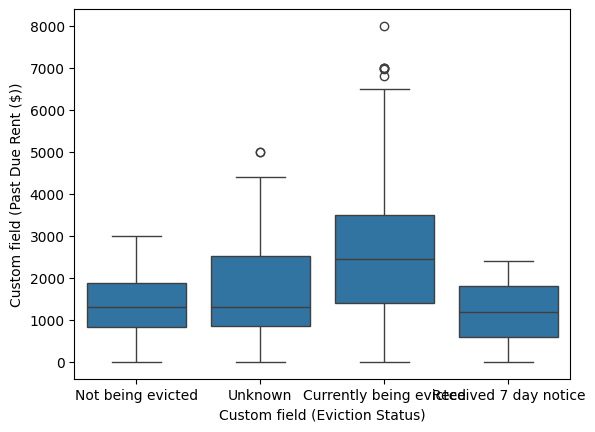

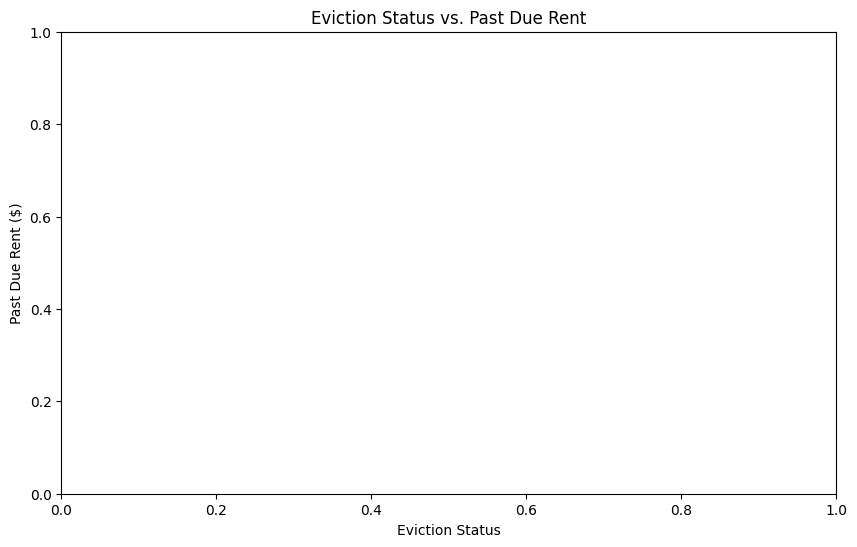

In [26]:
# plot eviction status against past due rent as a box plot
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(x='Custom field (Eviction Status)', y='Custom field (Past Due Rent ($))', data=clean_intakes)
plt.figure(figsize=(10, 6))
plt.title('Eviction Status vs. Past Due Rent')
plt.xlabel('Eviction Status')
plt.ylabel('Past Due Rent ($)')
plt.show()

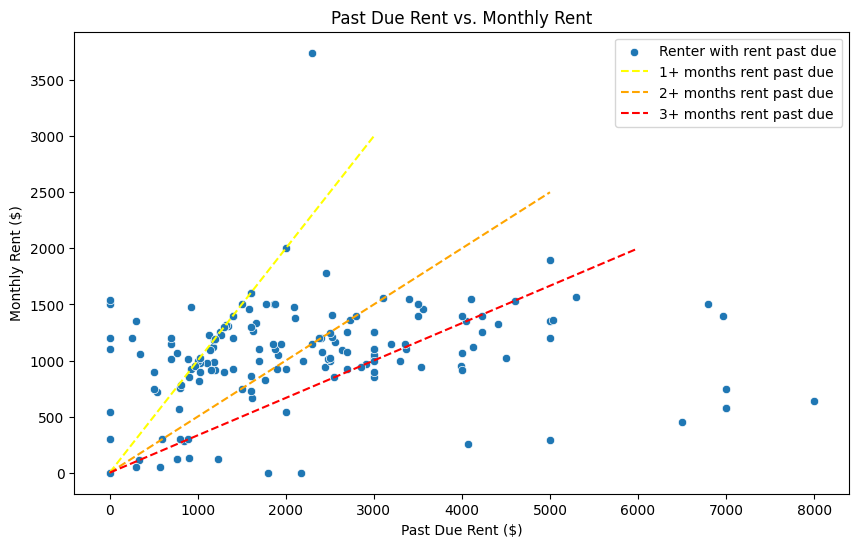

In [27]:
# plot rent past due against rent amount as a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Custom field (Past Due Rent ($))', y='Custom field (Monthly Rent ($))', data=clean_intakes)
plt.title('Past Due Rent vs. Monthly Rent')
plt.xlabel('Past Due Rent ($)')
plt.ylabel('Monthly Rent ($)')
plt.plot([0, 3000], [0, 3000], color='yellow', linestyle='--')
plt.plot([0, 5000], [0, 2500], color='orange', linestyle='--')
plt.plot([0, 6000], [0, 2000], color='red', linestyle='--')
# create a legend to label the lines
plt.legend(['Renter with rent past due','1+ months rent past due', '2+ months rent past due', '3+ months rent past due'])
plt.show()

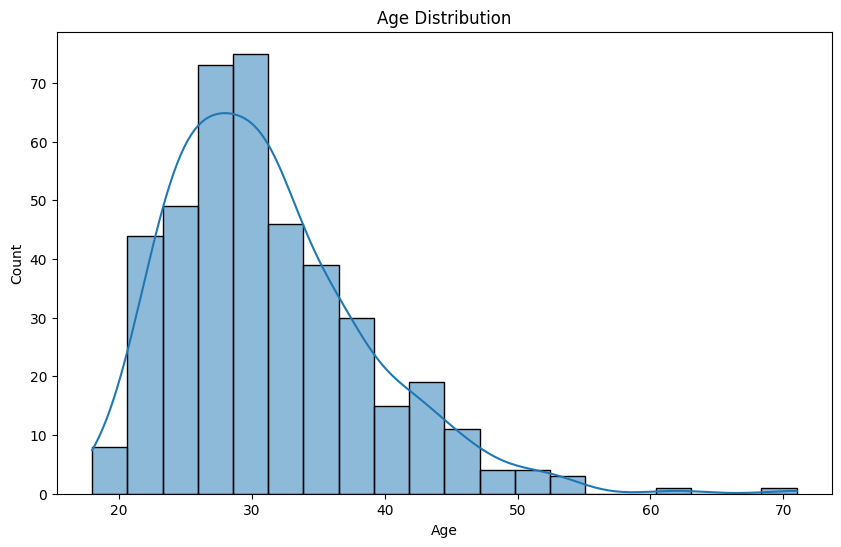

In [28]:
# plot clean_intakes age column
plt.figure(figsize=(10, 6))
sns.histplot(clean_intakes['Age at Intake'], bins=20, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

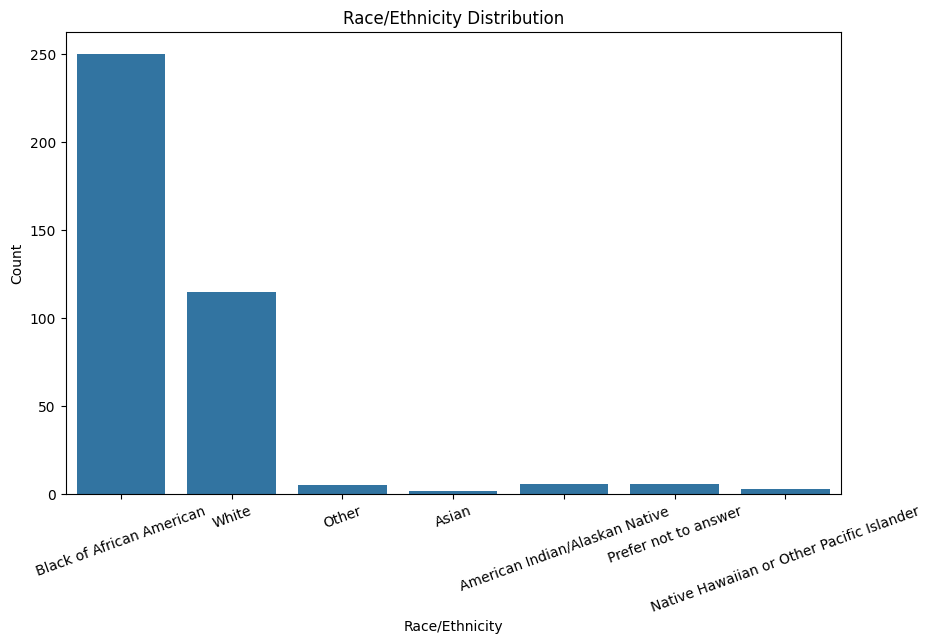

In [29]:
# plot the clean_intake races
plt.figure(figsize=(10, 6))
sns.countplot(x='Custom field (Race/Ethnicity)', data=clean_intakes)
plt.title('Race/Ethnicity Distribution')
plt.xlabel('Race/Ethnicity')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.show()

In [30]:
# clean_intakes.to_csv('/content/drive/MyDrive/Colab Notebooks/Group Project/ultra_clean_intakes_masked.csv', index=False)
# clean_household.to_csv('/content/drive/MyDrive/Colab Notebooks/Group Project/ultra_clean_household_members_long_v2.csv', index=False)
# print("Saved clean_intakes_v2.csv and clean_household_members_v2.csv to Google Drive!")